In [32]:
import numpy as np
import matplotlib.pyplot as plt

# Exercise 1: BBP Phase Transition in the Spin Glass Card Game

Given a ground truth configuration $s^*\in \mathbb{R}^N$ with $s_i^*\in \{\pm 1\}$, we observe a symmetric matrix $Y\in \mathbb{R}^{N\times N}$ constructed as:
$$ Y = \frac{1}{\sqrt{N}}s^*s^{*\top} + W, \quad W_{ij}\sim \mathcal{N}(0, \Delta). $$
The task is to recover the original hidden card assignments $s^*$, up to a sign change, from the noisy pairwise informations $Y$.

1. Write a function to generate the *spin glass card game dataset*. This function should generate a $N$-dimensional vector $s^*$ with random components $s_i^* \in \{\pm1\}$ and return it together with the matrix $Y.$ *Hint: W is a symmetric noise matrix with i.i.d. entries sampled from a Gaussian distribution $\mathcal{N}(0,\Delta)$, be careful when generating it.*

In [33]:
def card_game_dataset(N, Delta):
    s = np.random.choice([1., -1.], size=(N,1))
    W = np.random.randn(N, N) * np.sqrt(Delta)
    W = np.tril(W) + np.tril(W, -1).T
    Y = s @ s.T / np.sqrt(N) + W
    return s, Y

2. For multiple values of $\Delta \in [0,1]$, diagonalize the matrix $Y$ and plot a histogram of its eigenvalue spectrum. What do you observe? *Hint: Use numpy.linalg.eigh to solve the diagonalization problem.*

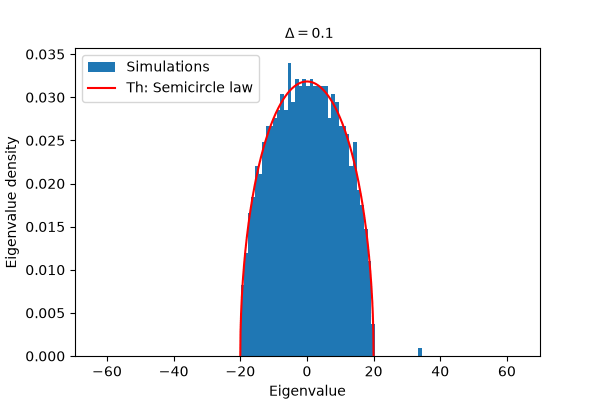

In [34]:
from matplotlib.animation import ArtistAnimation
from matplotlib.text import Text
from IPython.display import Image, display

N = 1000
Deltas = np.linspace(0.1, 1, 50)

fig, ax = plt.subplots(figsize=(6, 4))
frames = []

for Delta in Deltas:
    _, Y = card_game_dataset(N, Delta)
    eval, evec = np.linalg.eigh(Y)

    _, _, bars = ax.hist(eval, bins=50, density=True, color='C0', label='Simulations')
    x = np.linspace(-2*np.sqrt(N*Delta), 2*np.sqrt(N*Delta), 500)
    density = np.sqrt(np.maximum(4*N*Delta - x**2, 0)) / (2*np.pi*N*Delta)
    curve, = ax.plot(x, density, 'r-', label=r'$\text{Th: Semicircle law}$')
    label = ax.text(0.5, 1.02, rf' $\Delta = {Delta:g}$', transform=ax.transAxes,ha='center', va='bottom')
    frames.append([*bars, curve, label])
ax.set_xlabel(r'$\text{Eigenvalue}$')
ax.set_ylabel(r'$\text{Eigenvalue density}$')
ax.legend(handles=[bars[0], curve], loc='upper left')
ax.set_xlim(ax.get_xlim())
ax.set_ylim(ax.get_ylim())
ani = ArtistAnimation(fig, frames, interval=1000)
ani.save('exercise1_spectrum.gif', writer='pillow', fps=7)
plt.close(fig)
display(Image(filename='exercise1_spectrum.gif'))

3. We know from the course that the maximum likelihood estimator of the cards values $s_i^*$ is the leading eigenvector of $Y$, $e_i^{\max}$. To obtain binary spin predictions, we infer the $s_i^*$ using the spectral estimator $\hat{s}_i = \text{sign}(e_i^{\max})$. Compute the alignment $$Q = {\rm abs}\left(\frac{1}{N} \sum_{i=1}^N s_i^* \hat{s}_i \right)$$
for different values of noise variance $\Delta \in [0,2]$.  Notice the absolute value in order to take into account the symmetry $s \to -s$ in the problem. Average over 10 random realizations for each considered value of $\Delta$, and plot $Q(\Delta)$. You should get a hint that there is a phase transition at a certain value of $\Delta$, which one? How is the spectrum of Y related to the recovery of the two groups? *Note: this is a BBP (Baik–Ben Arous–Péché) phase transition.*

Text(0, 0.5, '$Q$')

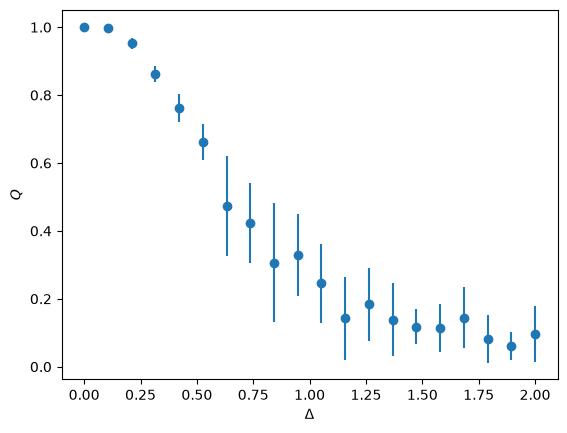

In [35]:
N = 500
Deltas = np.linspace(0, 2, 20)

Q = []
exps = 10
for Delta in Deltas:
    q = []
    for exp in range(exps):
        S, Y = card_game_dataset(N, Delta)
        eval, evec = np.linalg.eigh(Y)
        max_evec = evec[:, np.argmax(eval)]
        q.append(np.absolute((np.sign(max_evec) * S.reshape(-1)).mean()))
    Q.append(q)
Q = np.array(Q)
plt.errorbar(Deltas, Q.mean(axis=1), yerr=Q.std(axis=1), fmt='o')
plt.xlabel(r'$\Delta$')
plt.ylabel(r'$Q$')

# Exercise 2: Spin Glass Card Game with Monte Carlo


With the objective to recover the original signal $s^*$, we can construct different estimators, that require averaging over high dimensional probability distributions. To compute these averages, we resort to Monte Carlo Sampling. 

You saw in the lectures that the estimator $\hat s(Y)$ minimizing the expected (over the posterior) square loss
$$
\text{MSE}=\mathbb E_{s^*|Y}\left[\frac{1}{N}\sum_i \left(\hat s(Y)_i-s^*_i\right)^2\right],
$$
is given by the mean of the posterior
$$
\hat s_{mmse}(Y)_i=\mathbb E_{s|Y} \left[ s_i\right].
$$
It is called Bayes estimator, or minimum mean square error estimator (mmse). In order to compute the magnetizations we implement a Monte Carlo Markov Chain algorithm that samples from the posterior.

> *Connection to statistical physics: Consider a system of $N$ binary spins $s_1,\dots,s_N$, whose joint probability distribution is given by the posterior*
>
> $$
> P(s|Y)=\frac{1}{Z(Y)} e^{-H(s;Y)}, \qquad H(s;Y)=-\frac{1}{\Delta\sqrt{N}}\sum_{i<j}Y_{ij}s_is_j.
> $$
>
> *Then the Bayes estimator is nothing but the magnetizations of the spins $s_i$. Denoting the average with respect to $P(s|Y)$ with $\langle\cdot\rangle$ we can write*
>
> $$
> m_i=\langle s_i \rangle=\hat s_{mmse}(Y)_i.
> $$
>
> *For the single configuration $s$ we define its overlap with the ground truth $s^*$ as $\text{ov}(s,s^*)=\frac{1}{N}\sum_i s_is^*_i$*

0. First let's define the model. We consider a slightly different setting as before. The ground truth signal is again $s^* =(s^*_1,\dots,s^*_N)$, $s^*_i=\pm 1$ with equal probability. We build the matrix

   $$
   \begin{cases}Y_{ij}=\frac{s_i^*s_j^*}{\sqrt{N}}+\sqrt{\Delta}W_{ij}, &&  i\neq j,\\  Y_{ij}=0 && i= j, \end{cases}
   $$

   where $W_{ij}\sim N(0,1)$ are all independent over $i<j$ and $W_{ij}=W_{ji}$ so that $Y$ is symmetric.
   $\{Y_{ij}\}_{i\in [N],j\in[N]}$ is our data. *Note: the difference is in the $Y_{ii}$ set to zero.*

In [36]:
# Generating the planted signal (or ground truth)
N = 128  # Number of spins
Delta = 0.5  # Noise variance

np.random.seed(1234)
s_star, Y = card_game_dataset(N, Delta)
s_star = s_star.squeeze() # to remove all dimensions of size 1 from the array
for i in range(N): # Set to zero the diagonal elements
    Y[i, i] = 0

We are given $Y$ and want to sample from the posterior $P(s|Y)$. MCMC methods are based on designing a Markov chain whose stationary distribution is the distribution we want to sample from. A Markov chain is a stochastic process consisting in a sequence of random variables $\{s^{(t)}\}_{t\in\mathbb N}$. We will initialize the Markov chain in a random state and then update its state $s^{(t)}$ according to a chosen rule. There are many different Markov chains that have the same stationary probability. Here we will first implement the Metropolis rule for updating the state $s^{(t)}$.

### Metropolis

1. Let $s^{(t)}$ be the current state fo the Markov chain.
We draw an index $i\sim \mathrm{Unif}([N])$ uniformly at random and propose to flip the spin $s_i$.
Let $s'=(s^{(t)}_1,\dots,s^{(t)}_{i-1},-s^{(t)}_i,s^{(t)}_{i+1},\dots,s^{(t)}_N)$ be the new proposed state.
We then compute the acceptance probability $$P_{acc}(s^{(t)},s')=\min\left(1, \frac{P(s'|Y)}{P(s^{(t)}|Y)}\right).$$
We accept the proposal ($s^{(t+1)}=s'$) with probability $P_{acc}(s^{(t)},s')$. In practice, we draw a random variable $u$ uniformly distributed in $[0,1]$ and if $u<P_{acc}(s^{(t)},s')$, we set $s^{(t+1)}=s'$, otherwise we set $s^{(t+1)}=s^{(t)}$.

> *Special case of Boltzmann measures: When we want to sample from a probability of the form $P(s) \propto e^{-H(s)}$, the acceptance probability can be written as $P_{acc}(s^{(t)},s')=\min\{1, \exp(H(s^{(t)})-H(s'))\}$. In the particular case of the planted spin glass we have*
>
> $$
> H(s')-H(s^{(t)})=\frac{2 s_i^{(t)}}{\Delta\sqrt{N}}\sum_k Y_{ik} s^{(t)}_k
> $$
>
> *Notice that the Hamiltonian is invariant under the transformation $s\to-s$, so when running the MCMC we might end up correlating either with $s$ or with $-s$. As a consequence $m$ might either be positive or negative.*


In [37]:
def energy_difference(s, i, Y, Delta):
    '''
    Arguments:
    (s) current state, (i) flipped index, (Y) measurement matrix, (Delta) noise variance.
    Returns: 
    H(s')-H(s^t), where s' is obtained by flipping spin i in s^t.
    '''
    return 2*s[i]*np.einsum("k,k->", Y[i], s)/(np.sqrt(Y.shape[0])*Delta)

# Uniformly random initial configuration to start the MCMC
np.random.seed(0)
s0 = 2*np.random.binomial(n=1, p=0.5, size=[N])-1

In [38]:
# Here are some quantities we want to keep track of during the dynamics
overlaps = [] # Keeping track of the overlap through time
energies = [-np.einsum('ij,i,j->', Y, s0, s0)/(2*np.sqrt(N)*Delta)] # Keep track of all the states visited by the Markov chain
state_history = [np.copy(s0)]

T = 10000
s = np.copy(s0) # Current state
np.random.seed(10)
for t in range(T):

    # Returns a uniformly distributed integer between 0 and N-1, extremes included
    i = np.random.randint(low=0, high=N)
    delta_H = energy_difference(s, i, Y, Delta)
    # YOUR code here
    prob_accept = min([1, np.exp(-delta_H)])

    if (np.random.rand() < prob_accept):
        s[i] = -s[i] # If accepted, flip the spin
        energies.append(energies[-1]+delta_H)
    else:
        energies.append(energies[-1])

    overlaps.append(np.mean(s*s_star))
    state_history.append(np.copy(s))

2. Once your Monte Carlo finally runs, experiment making some plots by running the cell below. You will plot overlaps and energies of configurations as a function of time. Are you seeing what you would expect? If you have time you can change the value of $\Delta$ (for example to something larger than 1) and look for the differences.

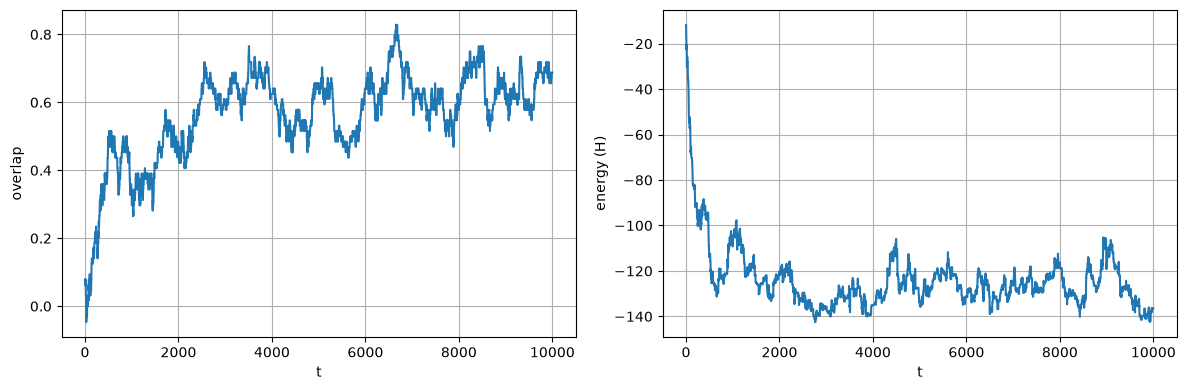

In [39]:
# Plot the overlap and energy against time.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(overlaps)
axes[0].set_ylabel("overlap")
axes[1].plot(energies)
axes[1].set_ylabel("energy (H)")
axes[0].set_xlabel("t")
axes[0].grid()
axes[1].set_xlabel("t")
axes[1].grid()
fig.tight_layout()
plt.show()

### Computing averages from the MCMC
Suppose that we want to compute the average over the posterior of an observable $A(s)$. To do this, we use the fact that (under the ergodicity assumption) the time averages over the Markov chain converge to the ensemble averages. Explicitely,
$$
\lim_{T\to\infty} \frac{1}{T}\sum_{t=0}^T A(s^{(t)})=\langle A \rangle=\sum_{s} P(s|Y) A(s),
$$
But in practice things are more involved.

As you saw, the Monte Carlo Markov chain needs some time to thermalize, before it starts sampling from the equilibrium measure. Configurations encountered in this initial *burn in* phase are not representative of the posterior, thus they should be discarded.
Let $T_\mathrm{therm}$ be the time needed by the Markov chain to reach equilibrium, and $T$ the maximum time of the simulation. Then we approximate
$$
\langle A \rangle \approx \frac{1}{T-T_\mathrm{therm}}\sum_{t=T_\mathrm{therm}}^T A(s^{(t)})
$$

3. Remember that $\hat s_{mmse}(Y)_i=m_i=\langle s_i\rangle=\mathbb E_{s|Y} \left[ s_i\right]$ is the minimum mean square error estimator. Approximating the average with the procedure explained above, compute the MMSE estimator. What do you think is a reasonable value for $T_\mathrm{therm}$? 


In [40]:
state_history = np.stack(state_history) # to stack the sequence of states together into a single NumPy array along a new axis

# Compute the mmse estimator from state_history using the procedure explained above.
T_therm = 3000
mmse_estimator = np.mean(state_history[T_therm:, :], axis=0)

mmse_estimator[:20] # to check that the result makes sense

array([ 0.10555635, -0.804028  ,  0.97771747, -0.83459506,  0.41779746,
        1.        ,  0.83459506, -0.93572347, -0.80088559,  0.21611198,
       -0.86916155, -0.71118412,  0.9245822 ,  1.        , -0.45979146,
        1.        ,  0.77660334,  0.60348522,  0.87058992,  1.        ])

4. Compute the mean squared error between the estimated signal and the true signal, considering both possible signs of the true signal, and keep the smaller one.

In [41]:
mse = min([np.mean((mmse_estimator-s_star)**2), np.mean((mmse_estimator+s_star)**2)])
print("mean square error =", mse)

mean square error = 0.3816126679293127


### Estimating $T_\mathrm{therm}$
 How do we know when our Markov chain has thermalized? In general there is no good answer to this question, however several heuristics can be used.
 

*   Look at when some observables (e.g. the energy) are stationary, i.e. their value stops drifting and fluctuates around a constant level.
*   Initialize two independent Markov chains, one random $s^{(0)}$ independent of $s^*$, and the other at $s^*$. Run the two Markov chains in parallel: $T_\mathrm{therm}$ is the time at which the observables from the two chains have roughly the same value. This approach has the drawback of requiring the knowledge of $s^*$, which we normally don't have. However in some cases we know the structure of the ordered state (e.g. Ising, where $s_i=1 \;\forall i$), so the method can be applied.

Let's try this second approach: we run a Monte Carlo Markov chain initialized from the planted configuration $s^*$ and compare the energy and overlap.


In [42]:
# First we save the overlaps and energies obtained with the random initialization
overlaps_rand_s0 = overlaps.copy()
energies_rand_s0 = energies.copy()

5. Re-execute the MCMC code, this time initializing with $s^{(0)}=s^*$. Remember to re-initialize all the variables.

In [43]:
s0 = np.copy(s_star)

overlaps = [] # Keeping track of the overlap through time
energies = [-np.einsum('ij,i,j->', Y, s0, s0)/(2*np.sqrt(N)*Delta)]
state_history = [np.copy(s0)]

T = 10000
s = np.copy(s0)  # Current state
for t in range(T):

    # Returns a uniformly distributed integer between 0 and N-1, extremes included
    i = np.random.randint(low=0, high=N)
    delta_H = energy_difference(s, i, Y, Delta)
    
    prob_accept = min([1, np.exp(-delta_H)])

    if (np.random.rand() < prob_accept):
        s[i] = -s[i] # If accepted, flip the spin
        energies.append(energies[-1]+delta_H)
    else:
        energies.append(energies[-1])

    overlaps.append(np.mean(s*s_star))
    state_history.append(np.copy(s))

6. Plot here the overlaps from the Markov chain with random initialization and the Markov with planted initialization. Does it match your estimation of $T_\mathrm{therm}$.

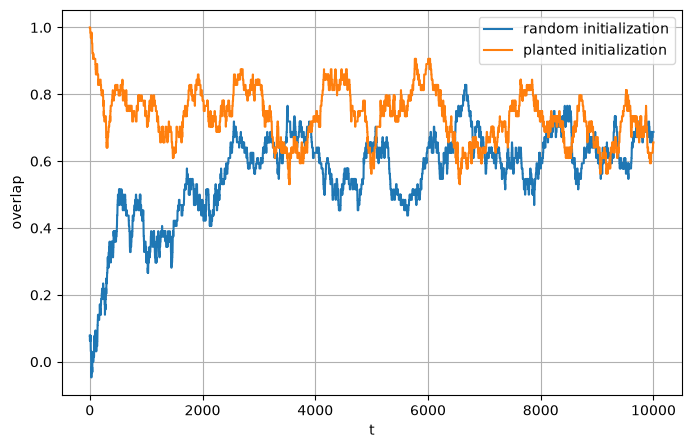

In [44]:
plt.figure(figsize=(8, 5))
plt.plot(overlaps_rand_s0, label='random initialization')
plt.plot(overlaps, label='planted initialization')
plt.grid()
plt.xlabel('t')
plt.ylabel('overlap')
plt.legend()